# Analysis of Apartment Sale Listings

**Goals and tasks:** Determine the market value of real estate objects. The task is to establish the parameters for building an automated system that detects anomalies and fraudulent activity.

**Plan:**
- 1. Data exploration
- 2. Data preprocessing
- 3. Adding extra data to the table
- 4. Exploratory data analysis
    - 4.1 Parameters: area, price, number of rooms, ceiling height
    - 4.2 Time of selling an apartment
    - 4.3 Rare and outlying values
    - 4.4 Factors that affect the price of an apartment
    - 4.5 Price per square meter in different localities
    - 4.6 Boundary of the central district in Saint Petersburg
    - 4.7 Apartments in the central district of Saint Petersburg
- 5. Overall conclusion

**Data description:**
Data of an apartment sale listing service for Saint Petersburg and neighboring localities over several years.
Both automatically collected and manually filled data is present.
- `airports_nearest` - distance to the nearest airport in meters (m)
- `balcony` - number of balconies
- `ceiling_height` - ceiling height (m)
- `cityCenters_nearest` - distance to the city center (m)
- `days_exposition` - how many days the listing was posted (from publication to removal)
- `first_day_exposition` - publication date
- `floor` - floor
- `floors_total` - total number of floors in the building
- `is_apartment` - apartments (boolean)
- `kitchen_area` - kitchen area in square meters (sq m)
- `last_price` - price at the moment the listing was removed
- `living_area` - living area in square meters (sq m)
- `locality_name` - name of the locality
- `open_plan` - open plan (boolean)
- `parks_around3000` - number of parks within 3 km
- `parks_nearest` - distance to the nearest park (m)
- `ponds_around3000` - number of ponds within 3 km
- `ponds_nearest` - distance to the nearest pond (m)
- `rooms` - number of rooms
- `studio` - studio apartment (boolean)
- `total_area` - area of the apartment in square meters (sq m)
- `total_images` - number of photos of the apartment in the listing

*Note:* apartments are non-residential premises that do not belong to the housing stock but have the necessary conditions for living.

## Step 1. Data Exploration

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
# read the data from the .csv file with read_csv()
real_estate = pd.read_csv('real_estate_data.csv',sep='\t')
# print the first 10 rows of the table with head()
display(real_estate.head(10))

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,13000000.0,108.00,2019-03-07T00:00:00,3,2.70,16.0,51.00,8,NaN,...,25.00,NaN,Санкт-Петербург,18863.0,16028.0,1.0,482.0,2.0,755.0,NaN
1,7,3350000.0,40.40,2018-12-04T00:00:00,1,NaN,11.0,18.60,1,NaN,...,11.00,2.0,посёлок Шушары,12817.0,18603.0,0.0,NaN,0.0,NaN,81.0
2,10,5196000.0,56.00,2015-08-20T00:00:00,2,NaN,5.0,34.30,4,NaN,...,8.30,0.0,Санкт-Петербург,21741.0,13933.0,1.0,90.0,2.0,574.0,558.0
3,0,64900000.0,159.00,2015-07-24T00:00:00,3,NaN,14.0,NaN,9,NaN,...,NaN,0.0,Санкт-Петербург,28098.0,6800.0,2.0,84.0,3.0,234.0,424.0
4,2,10000000.0,100.00,2018-06-19T00:00:00,2,3.03,14.0,32.00,13,NaN,...,41.00,NaN,Санкт-Петербург,31856.0,8098.0,2.0,112.0,1.0,48.0,121.0
5,10,2890000.0,30.40,2018-09-10T00:00:00,1,NaN,12.0,14.40,5,NaN,...,9.10,NaN,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
6,6,3700000.0,37.30,2017-11-02T00:00:00,1,NaN,26.0,10.60,6,NaN,...,14.40,1.0,посёлок Парголово,52996.0,19143.0,0.0,NaN,0.0,NaN,155.0
7,5,7915000.0,71.60,2019-04-18T00:00:00,2,NaN,24.0,NaN,22,NaN,...,18.90,2.0,Санкт-Петербург,23982.0,11634.0,0.0,NaN,0.0,NaN,NaN
8,20,2900000.0,33.16,2018-05-23T00:00:00,1,NaN,27.0,15.43,26,NaN,...,8.81,NaN,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
9,18,5400000.0,61.00,2017-02-26T00:00:00,3,2.50,9.0,43.60,7,NaN,...,6.50,2.0,Санкт-Петербург,50898.0,15008.0,0.0,NaN,0.0,NaN,289.0


In [3]:
# study the table structure with info(): data types, number of rows and columns, missing values.
real_estate.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  object 
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  object 
 15  airports_nearest   

### Conclusions

The data is read from the .csv file and saved in the variable `real_estate`. It has 22 variables and 23699 records. There is a lot of missing data in the columns `ceiling_height`, `is_apartment`, `balcony`, `parks_nearest`, `ponds_nearest` and others. Next, each column is examined to handle the missing and unreliable values.

## Step 2. Data Preprocessing

Examine the columns to find missing and unreliable data.

- Start with the number of rooms (column `rooms`).

In [4]:
# look at the distribution of the number of rooms with value_counts()
display(real_estate['rooms'].value_counts())

1     8047
2     7940
3     5814
4     1180
5      326
0      197
6      105
7       59
8       12
9        8
10       3
11       2
14       2
15       1
19       1
16       1
12       1
Name: rooms, dtype: int64

The number of rooms cannot be 0 (there are 197 such values). Most likely the data was not filled in, or 0 was entered by mistake. Look at the total area of such listings. Plot the histogram of `total_area` for `rooms` = 0.

array([[<Axes: title={'center': 'total_area'}>]], dtype=object)

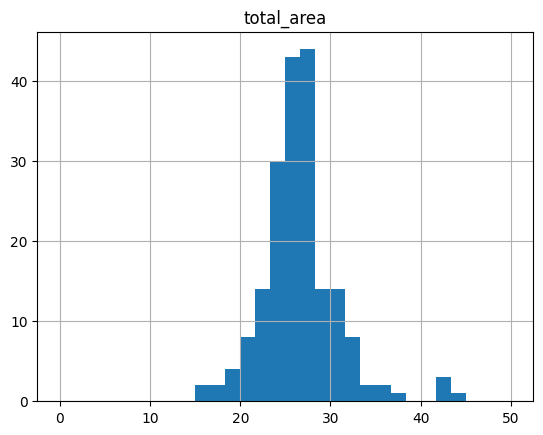

In [5]:
# select the rows with 'rooms' == 0 with loc[] and plot the histogram of 'total_area' with hist().
# split the histogram into 30 bins (bins=30), limit 'total_area' to < 50 (sq m)
real_estate.loc[real_estate['rooms'] == 0].hist('total_area', bins=30, range=(0, 50))

Apartments with an area below 40 sq m are most likely one-room. Replace `rooms` in such listings with 1.
For larger apartments it is hard to judge the number of rooms. Keep the zeros in such records and remember that their number of rooms is unknown.

In [6]:
# in the slice where `rooms` = 0 and `total_area` < 40 set `rooms` = 1.
real_estate.loc[(real_estate['rooms'] == 0) & (real_estate['total_area'] < 40), 'rooms'] = 1
# print the number of the remaining records with zero `rooms`
print('Number of listings with zero rooms:', len(real_estate.loc[(real_estate['rooms'] == 0)]))

Number of listings with zero rooms: 9


- Examine the apartment price in the column `last_price`.

This column has no missing values, but the data type can be changed to integer. The fractional part does not distort the data, and the integer type takes less memory.

In [7]:
real_estate['last_price'] = real_estate['last_price'].astype('int64')

- Examine the publication date in the column `first_day_exposition`.

The data is the publication date of the listing. Convert the data type from `object` to `datetime` with `to_datetime`.

In [8]:
# pass the date format to to_datetime with the format parameter.
real_estate['first_day_exposition'] = pd.to_datetime(real_estate['first_day_exposition'], format='%Y-%m-%dT%H:%M:%S')

- Examine the ceiling height in the column `ceiling_height`.

In [9]:
print('Number of missing values in ceiling_height:', len(real_estate.loc[real_estate['ceiling_height'].isna()]))

Number of missing values in ceiling_height: 9195


Many values are missing (almost 50%), so they cannot be dropped. The authors of the listings may not have entered this data, or the information was lost because of a system failure when the database was uploaded or exported.
The missing values could be replaced with values from other listings in the same buildings, but there is no information about the addresses of the apartments.
Replacing the values with the mean or median can distort the data distribution. If possible, the data should be restored from the building addresses or requested from the data owners.
At this stage the values are left empty.

- Examine the total number of floors in the building in the column `floors_total`.

In [10]:
print('Number of missing values in floors_total:', len(real_estate.loc[real_estate['floors_total'].isna()]))
display(real_estate.loc[real_estate['floors_total'].isna()].head(10))

Number of missing values in floors_total: 86


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
186,12,11640000,65.20,2018-10-02,2,NaN,NaN,30.80,4,NaN,...,12.00,NaN,Санкт-Петербург,39197.0,12373.0,1.0,123.0,0.0,NaN,49.0
237,4,2438033,28.10,2016-11-23,1,NaN,NaN,20.75,1,NaN,...,NaN,0.0,Санкт-Петербург,22041.0,17369.0,0.0,NaN,1.0,374.0,251.0
457,4,9788348,70.80,2015-08-01,2,NaN,NaN,38.40,12,NaN,...,10.63,0.0,Санкт-Петербург,37364.0,8322.0,2.0,309.0,2.0,706.0,727.0
671,4,6051191,93.60,2017-04-06,3,NaN,NaN,47.10,8,NaN,...,16.80,0.0,Санкт-Петербург,22041.0,17369.0,0.0,NaN,1.0,374.0,123.0
1757,5,3600000,39.00,2017-04-22,1,NaN,NaN,NaN,9,NaN,...,NaN,0.0,Санкт-Петербург,22735.0,11618.0,1.0,835.0,1.0,652.0,77.0
1930,1,9750000,66.77,2016-05-13,2,NaN,NaN,NaN,4,NaN,...,NaN,0.0,Санкт-Петербург,39886.0,10660.0,1.0,2276.0,3.0,244.0,90.0
2392,7,5395770,53.00,2017-06-29,2,NaN,NaN,29.00,22,NaN,...,9.00,0.0,Санкт-Петербург,43074.0,10820.0,0.0,NaN,0.0,NaN,48.0
2846,4,2325000,27.80,2016-09-21,1,NaN,NaN,19.40,15,NaN,...,NaN,0.0,Санкт-Петербург,22041.0,17369.0,0.0,NaN,1.0,374.0,307.0
2952,10,6500000,54.30,2019-04-23,1,NaN,NaN,22.20,6,NaN,...,12.30,NaN,Санкт-Петербург,23606.0,3148.0,0.0,NaN,0.0,NaN,NaN
3031,9,6400000,56.70,2018-03-27,2,NaN,NaN,32.00,12,NaN,...,12.00,NaN,Кудрово,NaN,NaN,NaN,NaN,NaN,NaN,231.0


Few values are missing. The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments, etc.).
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored if the building address is available or the data owners are contacted.
Replacing a small number of missing values with the mean or median would not distort the data distribution much. But such replacements can distort the influence of the apartment location on its price (last floor - price). At this stage the rows with missing values are dropped.

In [11]:
real_estate = real_estate.loc[~(real_estate['floors_total'].isna())]
print('Number of remaining records:', len(real_estate))

Number of remaining records: 23613


Note that the data type of `floors_total` is float `float64`, but the number of floors is an integer. Change the data type to integer `int64`.

In [12]:
real_estate['floors_total'] = real_estate['floors_total'].astype('int64')

- Examine the living area in the column `living_area`.

In [13]:
print('Number of missing values in living_area:', len(real_estate.loc[real_estate['living_area'].isna()]))
display(real_estate.loc[real_estate['living_area'].isna()].head(10))

Number of missing values in living_area: 1870


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
3,0,64900000,159.0,2015-07-24,3,NaN,14,NaN,9,NaN,...,NaN,0.0,Санкт-Петербург,28098.0,6800.0,2.0,84.0,3.0,234.0,424.0
7,5,7915000,71.6,2019-04-18,2,NaN,24,NaN,22,NaN,...,18.9,2.0,Санкт-Петербург,23982.0,11634.0,0.0,NaN,0.0,NaN,NaN
30,12,2200000,32.8,2018-02-19,1,NaN,9,NaN,2,NaN,...,NaN,NaN,Коммунар,NaN,NaN,NaN,NaN,NaN,NaN,63.0
37,10,1990000,45.8,2017-10-28,2,2.5,5,NaN,1,NaN,...,NaN,NaN,поселок городского типа Красный Бор,NaN,NaN,NaN,NaN,NaN,NaN,196.0
44,13,5350000,40.0,2018-11-18,1,NaN,22,NaN,3,NaN,...,NaN,1.0,Санкт-Петербург,30471.0,11603.0,1.0,620.0,1.0,1152.0,NaN
59,15,6300000,46.5,2017-03-06,1,NaN,13,NaN,13,NaN,...,NaN,NaN,Санкт-Петербург,11125.0,14501.0,0.0,NaN,0.0,NaN,336.0
60,3,2740000,35.0,2018-01-01,1,NaN,12,NaN,8,NaN,...,NaN,NaN,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,11.0
81,9,10949000,68.0,2018-12-27,1,NaN,10,NaN,6,NaN,...,NaN,NaN,Санкт-Петербург,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82,3,4500000,80.5,2018-01-15,3,NaN,25,NaN,16,NaN,...,NaN,NaN,посёлок Шушары,12430.0,18217.0,0.0,NaN,0.0,NaN,60.0
116,18,10999000,97.2,2017-11-13,3,2.5,16,NaN,16,NaN,...,18.3,5.0,Санкт-Петербург,19426.0,21138.0,0.0,NaN,2.0,390.0,394.0


This column has quite many missing values (about 8% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments, etc.).
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored if the building address is available or the data owners are contacted.
The data cannot be restored from the available information. At this stage the missing values are left as they are.

- Examine whether the property is an apartment in the column `is_apartment`.

In [14]:
print('Number of missing values in is_apartment:', len(real_estate.loc[real_estate['is_apartment'].isna()]))

Number of missing values in is_apartment: 20838


This column has very many missing values. The data may not have been filled in initially, or it was lost because of a system failure when the database was uploaded or exported. This column is not needed for the further analysis, so the missing values can be left as they are.
The data type of `is_apartment` is `object`, although the variable takes only the values True and False. The table description also indicates the boolean type. Convert the data type from `object` to `bool`.

In [15]:
real_estate['is_apartment'] = real_estate['is_apartment'].astype('bool')

- Examine the kitchen area in the column `kitchen_area`.

In [16]:
print('Number of missing values in kitchen_area:', len(real_estate.loc[real_estate['kitchen_area'].isna()]))
display(real_estate.loc[real_estate['kitchen_area'].isna()].head(10))

Number of missing values in kitchen_area: 2231


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
3,0,64900000,159.0,2015-07-24,3,NaN,14,NaN,9,True,...,NaN,0.0,Санкт-Петербург,28098.0,6800.0,2.0,84.0,3.0,234.0,424.0
30,12,2200000,32.8,2018-02-19,1,NaN,9,NaN,2,True,...,NaN,NaN,Коммунар,NaN,NaN,NaN,NaN,NaN,NaN,63.0
37,10,1990000,45.8,2017-10-28,2,2.5,5,NaN,1,True,...,NaN,NaN,поселок городского типа Красный Бор,NaN,NaN,NaN,NaN,NaN,NaN,196.0
44,13,5350000,40.0,2018-11-18,1,NaN,22,NaN,3,True,...,NaN,1.0,Санкт-Петербург,30471.0,11603.0,1.0,620.0,1.0,1152.0,NaN
59,15,6300000,46.5,2017-03-06,1,NaN,13,NaN,13,True,...,NaN,NaN,Санкт-Петербург,11125.0,14501.0,0.0,NaN,0.0,NaN,336.0
60,3,2740000,35.0,2018-01-01,1,NaN,12,NaN,8,True,...,NaN,NaN,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,11.0
81,9,10949000,68.0,2018-12-27,1,NaN,10,NaN,6,True,...,NaN,NaN,Санкт-Петербург,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82,3,4500000,80.5,2018-01-15,3,NaN,25,NaN,16,True,...,NaN,NaN,посёлок Шушары,12430.0,18217.0,0.0,NaN,0.0,NaN,60.0
133,12,3150000,31.0,2018-03-23,1,NaN,25,NaN,6,True,...,NaN,NaN,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,78.0
144,1,2450000,27.0,2017-03-30,1,NaN,24,15.5,2,True,...,NaN,2.0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,181.0


This column has quite many missing values (about 10% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments, etc.).
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored by contacting the data owners.
The data cannot be restored from the available information. At this stage the missing values are left as they are.

- Examine the number of balconies in the column `balcony`.

In [17]:
display(real_estate.loc[real_estate['balcony'].isna()].head(10))

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,13000000,108.00,2019-03-07,3,2.70,16,51.00,8,True,...,25.00,NaN,Санкт-Петербург,18863.0,16028.0,1.0,482.0,2.0,755.0,NaN
4,2,10000000,100.00,2018-06-19,2,3.03,14,32.00,13,True,...,41.00,NaN,Санкт-Петербург,31856.0,8098.0,2.0,112.0,1.0,48.0,121.0
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,9.10,NaN,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,8.81,NaN,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
10,5,5050000,39.60,2017-11-16,1,2.67,12,20.30,3,True,...,8.50,NaN,Санкт-Петербург,38357.0,13878.0,1.0,310.0,2.0,553.0,137.0
16,11,6700000,82.00,2017-11-23,3,3.05,5,55.60,1,True,...,9.00,NaN,Санкт-Петербург,22108.0,10698.0,3.0,420.0,0.0,NaN,397.0
19,16,14200000,121.00,2019-01-09,3,2.75,16,76.00,8,True,...,12.00,NaN,Санкт-Петербург,38900.0,12843.0,0.0,NaN,0.0,NaN,97.0
23,11,2950000,32.00,2016-10-29,1,2.60,9,17.70,9,True,...,6.10,NaN,Санкт-Петербург,15414.0,14211.0,2.0,517.0,1.0,190.0,615.0
26,6,4050000,60.00,2017-04-28,4,NaN,5,43.00,4,True,...,7.00,NaN,Санкт-Петербург,11580.0,10510.0,0.0,NaN,1.0,95.0,265.0
30,12,2200000,32.80,2018-02-19,1,NaN,9,NaN,2,True,...,NaN,NaN,Коммунар,NaN,NaN,NaN,NaN,NaN,NaN,63.0


This column has quite many missing values (about 50% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments, etc.).
The missing values most likely mean that the apartment has no balcony. Replace them with 0.
Also change the data type of this column from `float64` to `int64`, since the number of balconies is an integer.

In [18]:
# replace the missing data in the column `balcony` with 0 using `fillna`.
# inplace=True replaces the data in the existing table in place.
real_estate['balcony'].fillna(0, inplace=True)

# change the data type of the column `balcony` with astype()
real_estate['balcony'] = real_estate['balcony'].astype('int64')

- Examine the name of the locality in the column `locality_name`.

In [19]:
print('Number of missing values in locality_name:', len(real_estate.loc[real_estate['locality_name'].isna()]))
display(real_estate.loc[real_estate['locality_name'].isna()].head(10))

Number of missing values in locality_name: 48


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
1097,3,8600000,81.7,2016-04-15,3,3.55,5,50.80,2,True,...,8.80,0,NaN,23478.0,4258.0,0.0,NaN,0.0,NaN,147.0
2033,6,5398000,80.0,2017-05-30,3,NaN,4,42.60,2,True,...,18.60,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34.0
2603,20,3351765,42.7,2015-09-20,1,NaN,24,15.60,3,True,...,10.70,0,NaN,22041.0,17369.0,0.0,NaN,1.0,374.0,276.0
2632,2,5130593,62.4,2015-10-11,2,NaN,24,33.10,21,True,...,8.20,0,NaN,22041.0,17369.0,0.0,NaN,1.0,374.0,256.0
3574,10,4200000,46.5,2016-05-28,2,NaN,5,30.80,5,True,...,6.50,0,NaN,27419.0,8127.0,0.0,NaN,1.0,603.0,45.0
4151,17,17600000,89.5,2014-12-09,2,3.00,8,39.62,7,True,...,13.38,0,NaN,25054.0,3902.0,1.0,485.0,3.0,722.0,869.0
4189,7,9200000,80.0,2015-12-10,3,4.00,4,52.30,3,False,...,10.40,0,NaN,21774.0,3039.0,1.0,690.0,1.0,953.0,223.0
4670,1,5500000,83.0,2015-08-14,3,NaN,7,NaN,6,True,...,NaN,0,NaN,26534.0,5382.0,1.0,446.0,1.0,376.0,350.0
5343,19,13540000,85.5,2016-01-20,3,NaN,7,59.10,5,False,...,8.30,4,NaN,10556.0,9538.0,1.0,67.0,0.0,NaN,303.0
5707,7,3700000,30.0,2016-04-29,1,NaN,24,20.00,23,True,...,NaN,0,NaN,21460.0,16788.0,0.0,NaN,1.0,170.0,49.0


Few values are missing in this column (48 records). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices, distances to airports, etc.).
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored if the building address is available or the data owners are contacted.
The data cannot be restored from the available information. Replace the missing values with `Unknown`.

In [20]:
real_estate['locality_name'].fillna('Unknown', inplace=True)

- Examine the distance to the nearest airport in the column `airports_nearest`.

In [21]:
print('Number of missing values in airports_nearest:', len(real_estate.loc[real_estate['airports_nearest'].isna()]))
display(real_estate.loc[real_estate['airports_nearest'].isna()].head(10))

Number of missing values in airports_nearest: 5532


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,9.10,0,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,8.81,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
12,10,3890000,54.00,2016-06-30,2,NaN,5,30.00,5,True,...,9.00,0,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,90.0
22,20,5000000,58.00,2017-04-24,2,2.75,25,30.00,15,True,...,11.00,2,деревня Кудрово,NaN,NaN,NaN,NaN,NaN,NaN,60.0
30,12,2200000,32.80,2018-02-19,1,NaN,9,NaN,2,True,...,NaN,0,Коммунар,NaN,NaN,NaN,NaN,NaN,NaN,63.0
37,10,1990000,45.80,2017-10-28,2,2.50,5,NaN,1,True,...,NaN,0,поселок городского типа Красный Бор,NaN,NaN,NaN,NaN,NaN,NaN,196.0
38,10,3150000,40.00,2018-03-29,1,2.75,18,16.30,9,True,...,11.60,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,103.0
47,17,3600000,56.10,2018-10-18,3,NaN,4,42.50,3,True,...,5.70,1,Гатчина,NaN,NaN,NaN,NaN,NaN,NaN,179.0
60,3,2740000,35.00,2018-01-01,1,NaN,12,NaN,8,True,...,NaN,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,11.0
62,0,4800000,78.60,2017-09-17,3,2.80,9,48.80,5,True,...,11.90,2,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,5.0


This column has quite many missing values (about 23% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments, etc.).
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored from the geoposition of the districts or by contacting the data owners.
The data cannot be restored from the available information. At this stage the missing values are left as they are.

- Examine the distance to the center in the column `cityCenters_nearest`.

In [22]:
print('Number of missing values in cityCenters_nearest:', len(real_estate.loc[real_estate['cityCenters_nearest'].isna()]))
display(real_estate.loc[real_estate['cityCenters_nearest'].isna()].head(10))

Number of missing values in cityCenters_nearest: 5509


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,9.10,0,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,8.81,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
12,10,3890000,54.00,2016-06-30,2,NaN,5,30.00,5,True,...,9.00,0,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,90.0
22,20,5000000,58.00,2017-04-24,2,2.75,25,30.00,15,True,...,11.00,2,деревня Кудрово,NaN,NaN,NaN,NaN,NaN,NaN,60.0
30,12,2200000,32.80,2018-02-19,1,NaN,9,NaN,2,True,...,NaN,0,Коммунар,NaN,NaN,NaN,NaN,NaN,NaN,63.0
37,10,1990000,45.80,2017-10-28,2,2.50,5,NaN,1,True,...,NaN,0,поселок городского типа Красный Бор,NaN,NaN,NaN,NaN,NaN,NaN,196.0
38,10,3150000,40.00,2018-03-29,1,2.75,18,16.30,9,True,...,11.60,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,103.0
47,17,3600000,56.10,2018-10-18,3,NaN,4,42.50,3,True,...,5.70,1,Гатчина,NaN,NaN,NaN,NaN,NaN,NaN,179.0
60,3,2740000,35.00,2018-01-01,1,NaN,12,NaN,8,True,...,NaN,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,11.0
62,0,4800000,78.60,2017-09-17,3,2.80,9,48.80,5,True,...,11.90,2,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,5.0


This column has quite many missing values (about 23% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments). The data is missing both for apartments in cities and in villages.
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored from the geoposition of the districts or by contacting the data owners.
The data cannot be restored from the available information. At this stage the missing values are left as they are.

- Examine the number of parks within 3 km in the column `parks_around3000`.

In [23]:
print('Number of missing values in parks_around3000:', len(real_estate.loc[real_estate['parks_around3000'].isna()]))
display(real_estate.loc[real_estate['parks_around3000'].isna()].head(10))

Number of missing values in parks_around3000: 5508


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,9.10,0,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,8.81,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
12,10,3890000,54.00,2016-06-30,2,NaN,5,30.00,5,True,...,9.00,0,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,90.0
22,20,5000000,58.00,2017-04-24,2,2.75,25,30.00,15,True,...,11.00,2,деревня Кудрово,NaN,NaN,NaN,NaN,NaN,NaN,60.0
30,12,2200000,32.80,2018-02-19,1,NaN,9,NaN,2,True,...,NaN,0,Коммунар,NaN,NaN,NaN,NaN,NaN,NaN,63.0
37,10,1990000,45.80,2017-10-28,2,2.50,5,NaN,1,True,...,NaN,0,поселок городского типа Красный Бор,NaN,NaN,NaN,NaN,NaN,NaN,196.0
38,10,3150000,40.00,2018-03-29,1,2.75,18,16.30,9,True,...,11.60,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,103.0
47,17,3600000,56.10,2018-10-18,3,NaN,4,42.50,3,True,...,5.70,1,Гатчина,NaN,NaN,NaN,NaN,NaN,NaN,179.0
60,3,2740000,35.00,2018-01-01,1,NaN,12,NaN,8,True,...,NaN,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,11.0
62,0,4800000,78.60,2017-09-17,3,2.80,9,48.80,5,True,...,11.90,2,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,5.0


This column has quite many missing values (about 23% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments). The data is missing both for apartments in cities and in villages.
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored from the geoposition of the districts or by contacting the data owners.
At this stage the missing values are left as they are, since there are too many of them.

- Examine the distance to the nearest park in the column `parks_nearest`.

In [24]:
print('Number of missing values in parks_nearest:', len(real_estate.loc[real_estate['parks_nearest'].isna()]))
display(real_estate.loc[real_estate['parks_nearest'].isna()].head(10))

Number of missing values in parks_nearest: 15568


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
1,7,3350000,40.40,2018-12-04,1,NaN,11,18.60,1,True,...,11.00,2,посёлок Шушары,12817.0,18603.0,0.0,NaN,0.0,NaN,81.0
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,9.10,0,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
6,6,3700000,37.30,2017-11-02,1,NaN,26,10.60,6,True,...,14.40,1,посёлок Парголово,52996.0,19143.0,0.0,NaN,0.0,NaN,155.0
7,5,7915000,71.60,2019-04-18,2,NaN,24,NaN,22,True,...,18.90,2,Санкт-Петербург,23982.0,11634.0,0.0,NaN,0.0,NaN,NaN
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,8.81,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
9,18,5400000,61.00,2017-02-26,3,2.5,9,43.60,7,True,...,6.50,2,Санкт-Петербург,50898.0,15008.0,0.0,NaN,0.0,NaN,289.0
11,9,3300000,44.00,2018-08-27,2,NaN,5,31.00,4,False,...,6.00,1,Ломоносов,48252.0,51677.0,0.0,NaN,0.0,NaN,7.0
12,10,3890000,54.00,2016-06-30,2,NaN,5,30.00,5,True,...,9.00,0,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,90.0
14,1,4400000,36.00,2016-06-23,1,NaN,6,17.00,1,True,...,8.00,0,Пушкин,20782.0,30759.0,0.0,NaN,1.0,96.0,203.0
17,6,4180000,36.00,2016-09-09,1,NaN,17,16.50,7,True,...,11.00,1,Санкт-Петербург,33564.0,14616.0,0.0,NaN,1.0,859.0,571.0


This column has quite many missing values (about 65% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments). The data is missing both for apartments in cities and in villages.
The data may not have been entered by the authors of the listings (because there are no parks near the apartment), or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored from the geoposition of the districts or by contacting the data owners.
The data cannot be restored from the available information. At this stage the missing values are left as they are.

- Examine the number of ponds within 3 km in the column `ponds_around3000`.

In [25]:
print('Number of missing values in ponds_around3000:', len(real_estate.loc[real_estate['ponds_around3000'].isna()]))
display(real_estate.loc[real_estate['ponds_around3000'].isna()].head(10))

Number of missing values in ponds_around3000: 5508


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,9.10,0,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,8.81,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
12,10,3890000,54.00,2016-06-30,2,NaN,5,30.00,5,True,...,9.00,0,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,90.0
22,20,5000000,58.00,2017-04-24,2,2.75,25,30.00,15,True,...,11.00,2,деревня Кудрово,NaN,NaN,NaN,NaN,NaN,NaN,60.0
30,12,2200000,32.80,2018-02-19,1,NaN,9,NaN,2,True,...,NaN,0,Коммунар,NaN,NaN,NaN,NaN,NaN,NaN,63.0
37,10,1990000,45.80,2017-10-28,2,2.50,5,NaN,1,True,...,NaN,0,поселок городского типа Красный Бор,NaN,NaN,NaN,NaN,NaN,NaN,196.0
38,10,3150000,40.00,2018-03-29,1,2.75,18,16.30,9,True,...,11.60,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,103.0
47,17,3600000,56.10,2018-10-18,3,NaN,4,42.50,3,True,...,5.70,1,Гатчина,NaN,NaN,NaN,NaN,NaN,NaN,179.0
60,3,2740000,35.00,2018-01-01,1,NaN,12,NaN,8,True,...,NaN,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,11.0
62,0,4800000,78.60,2017-09-17,3,2.80,9,48.80,5,True,...,11.90,2,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,5.0


This column has quite many missing values (about 23% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments). The data is missing both for apartments in cities and in villages.
The data may not have been entered by the authors of the listings, or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored from the geoposition of the districts or by contacting the data owners.
At this stage the missing values are left as they are, since there are too many of them.

- Examine the distance to the nearest pond in the column `ponds_nearest`.

In [26]:
print('Number of missing values in parks_nearest:', len(real_estate.loc[real_estate['parks_nearest'].isna()]))
display(real_estate.loc[real_estate['parks_nearest'].isna()].head(10))

Number of missing values in parks_nearest: 15568


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
1,7,3350000,40.40,2018-12-04,1,NaN,11,18.60,1,True,...,11.00,2,посёлок Шушары,12817.0,18603.0,0.0,NaN,0.0,NaN,81.0
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,9.10,0,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.0
6,6,3700000,37.30,2017-11-02,1,NaN,26,10.60,6,True,...,14.40,1,посёлок Парголово,52996.0,19143.0,0.0,NaN,0.0,NaN,155.0
7,5,7915000,71.60,2019-04-18,2,NaN,24,NaN,22,True,...,18.90,2,Санкт-Петербург,23982.0,11634.0,0.0,NaN,0.0,NaN,NaN
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,8.81,0,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.0
9,18,5400000,61.00,2017-02-26,3,2.5,9,43.60,7,True,...,6.50,2,Санкт-Петербург,50898.0,15008.0,0.0,NaN,0.0,NaN,289.0
11,9,3300000,44.00,2018-08-27,2,NaN,5,31.00,4,False,...,6.00,1,Ломоносов,48252.0,51677.0,0.0,NaN,0.0,NaN,7.0
12,10,3890000,54.00,2016-06-30,2,NaN,5,30.00,5,True,...,9.00,0,Сертолово,NaN,NaN,NaN,NaN,NaN,NaN,90.0
14,1,4400000,36.00,2016-06-23,1,NaN,6,17.00,1,True,...,8.00,0,Пушкин,20782.0,30759.0,0.0,NaN,1.0,96.0,203.0
17,6,4180000,36.00,2016-09-09,1,NaN,17,16.50,7,True,...,11.00,1,Санкт-Петербург,33564.0,14616.0,0.0,NaN,1.0,859.0,571.0


This column has quite many missing values (about 60% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments). The data is missing both for apartments in cities and in villages.
The data may not have been entered by the authors of the listings (because there are no ponds near the apartment), or the values may have been lost because of a failure when the data was loaded into the database. The information can be restored from the geoposition of the districts or by contacting the data owners.
The data cannot be restored from the available information. At this stage the missing values are left as they are.

- Examine the number of days the listing was posted in the column `days_exposition`.

In [27]:
print('Number of missing values in days_exposition:', len(real_estate.loc[real_estate['days_exposition'].isna()]))
display(real_estate.loc[real_estate['days_exposition'].isna()].head(10))

Number of missing values in days_exposition: 3172


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,13000000,108.0,2019-03-07,3,2.70,16,51.00,8,True,...,25.0,0,Санкт-Петербург,18863.0,16028.0,1.0,482.0,2.0,755.0,NaN
7,5,7915000,71.6,2019-04-18,2,NaN,24,NaN,22,True,...,18.9,2,Санкт-Петербург,23982.0,11634.0,0.0,NaN,0.0,NaN,NaN
44,13,5350000,40.0,2018-11-18,1,NaN,22,NaN,3,True,...,NaN,1,Санкт-Петербург,30471.0,11603.0,1.0,620.0,1.0,1152.0,NaN
45,17,5200000,50.6,2018-12-02,2,2.65,9,30.30,7,True,...,7.0,0,Санкт-Петербург,30011.0,12872.0,0.0,NaN,0.0,NaN,NaN
46,17,6600000,52.1,2019-01-31,2,2.60,24,29.70,9,True,...,8.3,2,Санкт-Петербург,15114.0,12702.0,0.0,NaN,0.0,NaN,NaN
49,1,3050000,30.8,2018-11-22,1,2.50,9,18.00,7,True,...,6.0,0,Санкт-Петербург,45341.0,16603.0,1.0,675.0,0.0,NaN,NaN
52,20,11795000,136.0,2017-09-22,6,3.00,2,94.00,2,True,...,11.0,1,Санкт-Петербург,16510.0,6582.0,1.0,526.0,0.0,NaN,NaN
71,20,4850000,57.5,2019-03-27,3,2.50,9,39.00,8,True,...,6.2,0,Санкт-Петербург,33623.0,12267.0,1.0,334.0,1.0,333.0,NaN
81,9,10949000,68.0,2018-12-27,1,NaN,10,NaN,6,True,...,NaN,0,Санкт-Петербург,NaN,NaN,NaN,NaN,NaN,NaN,NaN
84,11,2400000,43.9,2019-03-13,2,NaN,2,27.46,1,True,...,5.2,0,Кировск,NaN,NaN,NaN,NaN,NaN,NaN,NaN


This column has quite many missing values (about 13% of all data). The rows with missing values cannot be assigned to one specific category (different listing dates, different prices and locations of apartments, etc.).
The data may have been lost because of a system failure when the database was exported.
It is also possible that the system did not enter the information because the listing had not been removed at the moment of the export.
The information can be restored by contacting the data owners.
At this stage it is assumed that the listings with missing values had not been removed, and they are left as they are.

Show the final result of the preprocessing.

In [28]:
real_estate.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 23613 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   total_images          23613 non-null  int64         
 1   last_price            23613 non-null  int64         
 2   total_area            23613 non-null  float64       
 3   first_day_exposition  23613 non-null  datetime64[ns]
 4   rooms                 23613 non-null  int64         
 5   ceiling_height        14495 non-null  float64       
 6   floors_total          23613 non-null  int64         
 7   living_area           21743 non-null  float64       
 8   floor                 23613 non-null  int64         
 9   is_apartment          23613 non-null  bool          
 10  studio                23613 non-null  bool          
 11  open_plan             23613 non-null  bool          
 12  kitchen_area          21382 non-null  float64       
 13  balcony         

### Conclusions

- The table contains a large number of missing values (up to 65% in a column).
- The missing values were analyzed and filled where possible (for example, the missing numbers of balconies were replaced with 0).
- The possible reasons for the missing values are given for each variable. The main reasons are missing information when the listing was filled in and system failures when the database was uploaded or exported.
- The column `rooms` was analyzed additionally. The zero values were replaced with 1 (one-room apartment) when the total area `total_area` < 40 sq m.
- The data types were converted according to the table description and the meaning of the stored information.

## Step 3. Adding Extra Data to the Table

**1)** Calculate the price per square meter of an apartment.
To do this, divide the price `last_price` by the total area `total_area`. Round the result to one decimal place. Save the result in the column `meter_price`.

In [29]:
# round with round()
real_estate['meter_price'] = round(real_estate['last_price'] / real_estate['total_area'], 1)

**2)** Calculate the day of the week, the month and the year of the listing publication.
Use `.dt.weekday`, `.dt.month` and `.dt.year` respectively.
Take the publication date from the column `first_day_exposition`.
Save the results in the columns `publish_weekday`, `publish_month`, `publish_year`.

In [30]:
real_estate['publish_weekday'] = real_estate['first_day_exposition'].dt.weekday
real_estate['publish_month'] = real_estate['first_day_exposition'].dt.month
real_estate['publish_year'] = real_estate['first_day_exposition'].dt.year

**3)** Create the floor category of an apartment.
Take the data from the columns `floor` (floor of the apartment) and `floors_total` (number of floors in the building).
Save the result in the column `floor_cat`.
To define the category, create the function floor_category(). It takes a row of data, compares the floor of the apartment with the number of floors in the building and returns the name of the category. Then apply the function to all rows of the table with `apply`.

In [31]:
#  create the function `floor_category(row)` to find the floor category of an apartment
def floor_category(row):
    """
    input: row - row with the information about an apartment
    output: (object) - floor category of the apartment
    The function takes a row of data,
    compares the floor of the apartment `floor` with the number of floors in the building `floors_total`
    and returns the category:
    
    Category:           Description:
    first               first floor of the building
    last                last floor of the building
    other               all other floors
    """
    floor = row['floor']
    floors_total = row['floors_total']
    if floor == 1:
        return 'first'
    elif floor == floors_total:
        return 'last'
    else:
        return 'other'

# apply the function floor_category to all rows of the table 'real_estate' with apply
real_estate['floor_cat'] = real_estate.apply(floor_category, axis=1)

**4)** Calculate the ratio of the living area to the total area of an apartment and the ratio of the kitchen area to the total area.
Take the data from the columns `living_area`, `total_area` and `kitchen_area`.
Save the results in the columns `living_to_total` and `kitchen_to_total` respectively.
Round the results to 2 decimal places.

In [32]:
real_estate['living_to_total'] = round(real_estate['living_area'] / real_estate['total_area'], 2)
real_estate['kitchen_to_total'] = round(real_estate['kitchen_area'] / real_estate['total_area'], 2)

In [33]:
# Final look of the table:
display(real_estate.head(10))

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,ponds_around3000,ponds_nearest,days_exposition,meter_price,publish_weekday,publish_month,publish_year,floor_cat,living_to_total,kitchen_to_total
0,20,13000000,108.00,2019-03-07,3,2.70,16,51.00,8,True,...,2.0,755.0,NaN,120370.4,3,3,2019,other,0.47,0.23
1,7,3350000,40.40,2018-12-04,1,NaN,11,18.60,1,True,...,0.0,NaN,81.0,82920.8,1,12,2018,first,0.46,0.27
2,10,5196000,56.00,2015-08-20,2,NaN,5,34.30,4,True,...,2.0,574.0,558.0,92785.7,3,8,2015,other,0.61,0.15
3,0,64900000,159.00,2015-07-24,3,NaN,14,NaN,9,True,...,3.0,234.0,424.0,408176.1,4,7,2015,other,NaN,NaN
4,2,10000000,100.00,2018-06-19,2,3.03,14,32.00,13,True,...,1.0,48.0,121.0,100000.0,1,6,2018,other,0.32,0.41
5,10,2890000,30.40,2018-09-10,1,NaN,12,14.40,5,True,...,NaN,NaN,55.0,95065.8,0,9,2018,other,0.47,0.30
6,6,3700000,37.30,2017-11-02,1,NaN,26,10.60,6,True,...,0.0,NaN,155.0,99195.7,3,11,2017,other,0.28,0.39
7,5,7915000,71.60,2019-04-18,2,NaN,24,NaN,22,True,...,0.0,NaN,NaN,110544.7,3,4,2019,other,NaN,0.26
8,20,2900000,33.16,2018-05-23,1,NaN,27,15.43,26,True,...,NaN,NaN,189.0,87454.8,2,5,2018,other,0.47,0.27
9,18,5400000,61.00,2017-02-26,3,2.50,9,43.60,7,True,...,0.0,NaN,289.0,88524.6,6,2,2017,other,0.71,0.11


### Conclusions

- The metrics were calculated according to the task and added to the main table.
- The names of the new columns were chosen according to the information they store.
- The new columns have missing values in the records where the source data was missing.

## Step 4. Exploratory Data Analysis

### 4.1 Parameters: Area, Price, Number of Rooms, Ceiling Height

**1)** Examine the area of the apartments in the column `total_area`. Plot the histogram of this parameter.

count    23613.000000
mean        60.340678
std         35.648988
min         12.000000
25%         40.000000
50%         52.000000
75%         69.800000
max        900.000000
Name: total_area, dtype: float64

99th percentile of total_area: 197.2


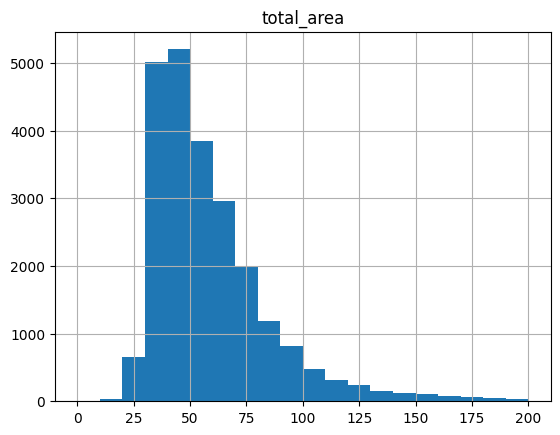

In [34]:
# print the distribution of the values of total_area with describe()
display(real_estate['total_area'].describe())
# find the .99 quantile of total_area with .quantile(.99)
print('99th percentile of total_area:', round(real_estate['total_area'].quantile(0.99), 1))
# plot the histogram of 'total_area' with hist().
# split the histogram into 20 bins (bins=20), limit 'total_area' to < 200 (sq m)
real_estate.hist('total_area', bins=20, range = (0, 200))
plt.show()

- The distribution of `total_area` is close to the Poisson distribution, without anomalous peaks.
- The minimum area of 12 sq m is a plausible value, possibly a room is being sold.
- The maximum value of 900 sq m is quite high but also plausible.
- 99% of the values are within the range 12 - 200 sq m. The other cases can be considered outliers.
- The median (52.0) is lower than the mean (60.3), so the data is slightly skewed to the left. This is normal: there are more small apartments, but very large ones contribute to the skew.

**2)** Examine the apartment price in the column `last_price`. Plot the histogram of this parameter.

count    2.361300e+04
mean     6.540555e+06
std      1.090172e+07
min      1.219000e+04
25%      3.400000e+06
50%      4.650000e+06
75%      6.799000e+06
max      7.630000e+08
Name: last_price, dtype: float64

99th percentile of last_price: 36000000.0


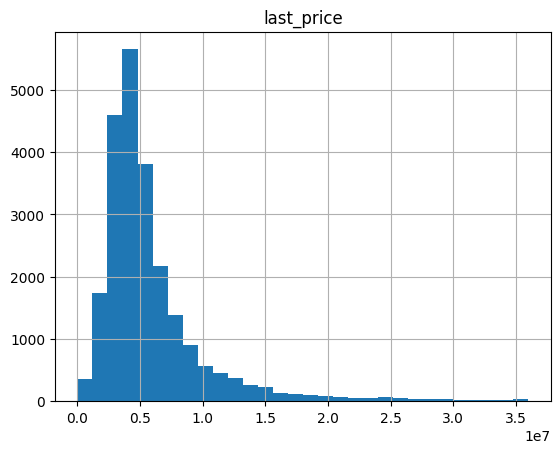

In [35]:
# print the distribution of the values of last_price with describe()
display(real_estate['last_price'].describe())
# find the 99th percentile of last_price with .quantile(.99)
print('99th percentile of last_price:', round(real_estate['last_price'].quantile(0.99), 1))
# plot the histogram of 'last_price' with hist().
# split the histogram into 30 bins (bins=30), limit 'last_price' to < 3.6*10**7 (.99 quantile)
real_estate.hist('last_price', bins=30, range = (0, 3.6*10**7))
plt.show()

- The distribution of `last_price` is close to the Poisson distribution, without anomalous peaks.
- The minimum price of 12190 is quite small but possible.
- The maximum value of 7.6*10^8 is quite high but also plausible.
- 99% of the values are below 3.6*10^7. The other cases can be considered outliers.
- The median 4.7\*10^6 is lower than the mean 6.5*10^6, so the data is skewed to the left. This is normal: there are more cheap apartments, but very expensive real estate contributes to the skew.

**3)** Examine the number of rooms in the column `rooms`. Plot the histogram of this parameter.

count    23613.000000
mean         2.078982
std          1.066875
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         19.000000
Name: rooms, dtype: float64

99th percentile of rooms: 5.0


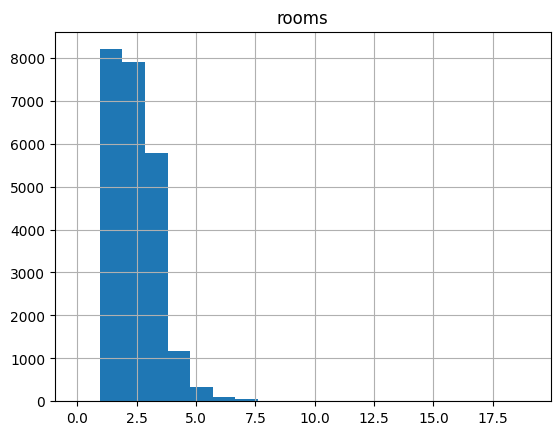

In [36]:
# print the distribution of the values of rooms with describe()
display(real_estate['rooms'].describe())
# find the 99th percentile of rooms with .quantile(.99)
print('99th percentile of rooms:', round(real_estate['rooms'].quantile(0.99), 1))
# plot the histogram of 'rooms' with hist().
# split the histogram into 20 bins (bins=20)
real_estate.hist('rooms', bins=20)
plt.show()

- The distribution of `rooms` is close to the Poisson distribution, without anomalous peaks.
- The anomalous zero values were handled in step 2. 9 zero values remain. They will not distort the distribution much and can be considered outliers.
- The maximum value of 19 is quite high but plausible.
- 99% of the values are below 6. The other cases can be considered outliers.
- The median and the mean are both 2, so the data is practically not skewed, since the vast majority of the apartments have 1, 2, 3 and 4 rooms. The spread of the values is very small.

**4)** Examine the ceiling height in the column `ceiling_height`. Plot the histogram of this parameter.

count    14495.000000
mean         2.771495
std          1.261445
min          1.000000
25%          2.520000
50%          2.650000
75%          2.800000
max        100.000000
Name: ceiling_height, dtype: float64

99.5th percentile of ceiling_height: 4.1
0.5th percentile of ceiling_height: 2.5


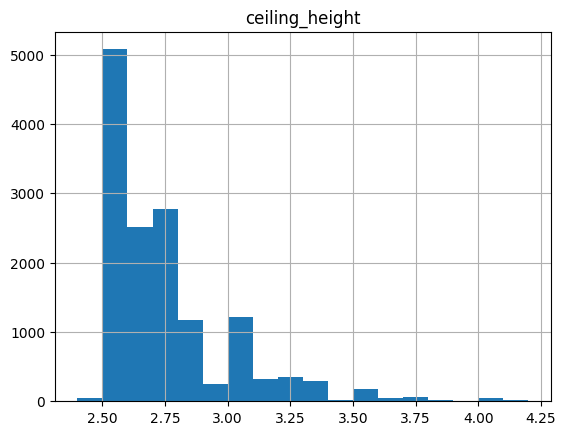

In [37]:
# print the distribution of the values of ceiling_height with describe()
display(real_estate['ceiling_height'].describe())
# find the 99.5th percentile of ceiling_height with .quantile(.995)
print('99.5th percentile of ceiling_height:', round(real_estate['ceiling_height'].quantile(0.995), 1))
# find the 0.5th percentile of ceiling_height with .quantile(.005)
print('0.5th percentile of ceiling_height:', round(real_estate['ceiling_height'].quantile(0.005), 1))
# plot the histogram of 'ceiling_height' with hist().
# split the histogram into 18 bins (bins=18),
# limit 'ceiling_height' to (2.4, 4.2), discarding 1% of abnormally high and low values
real_estate.hist('ceiling_height', bins=18, range = (2.4, 4.2))
plt.show()

- The distribution of `ceiling_height` is close to the Poisson distribution. There is a small anomaly at 3 m. It can be explained by the way the data was filled in (the height was rounded to 3 m when the real height was 2.9 or 3.1 m).
- The maximum value of 100 m is wrong, but there are few such values: 99% of the values are below 4 m. The other cases can be considered outliers, and they will not distort the distribution.
- The minimum value of 1 m is most likely wrong, but there are few such values: 99% of the values are above 2.5 m. The other cases can be considered outliers, and they will not distort the distribution much.
- The median and the mean are 2.65 and 2.77 respectively. The data is practically not skewed, since the vast majority of the apartments have a ceiling height of 2.5 - 3.5 m. The spread of the values is small. This may also explain the small anomalies in the Poisson-like distribution.

### 4.2 Time of Selling an Apartment

The time of selling an apartment is in the parameter `days_exposition`.
First find the 1st and 99th percentiles of the distribution to exclude rare values from the histogram.

In [38]:
# find the 99th percentile of rooms with .quantile(.99)
print('99th percentile of days_exposition:', round(real_estate['days_exposition'].quantile(0.99), 1))
# find the 1st percentile of days_exposition with .quantile(.01)
print('1st percentile of days_exposition:', round(real_estate['days_exposition'].quantile(0.01), 1))

99th percentile of days_exposition: 1067.0
1st percentile of days_exposition: 4.0


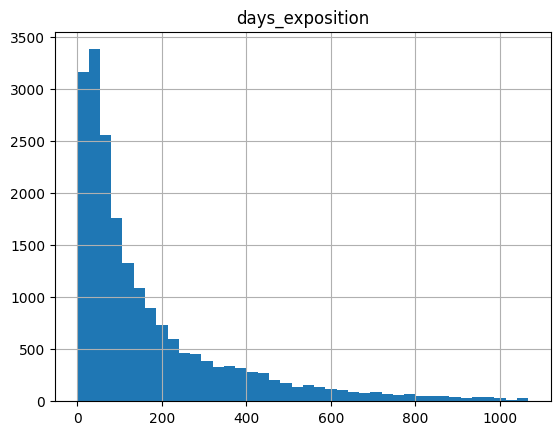

In [39]:
# plot the histogram of 'days_exposition' with hist().
# split the histogram into 40 bins (bins=40),
# limit the histogram to the values 0 - 1067
real_estate.hist('days_exposition', bins=40, range=(0,1067))
plt.show()

Now calculate the mean and the median and look at the distribution of the values with describe().

In [40]:
print('Mean selling time:', round(real_estate['days_exposition'].mean(),0))
print('Median selling time:', round(real_estate['days_exposition'].median(),0))
real_estate['days_exposition'].describe()

Mean selling time: 181.0
Median selling time: 95.0


count    20441.000000
mean       180.884839
std        219.685543
min          1.000000
25%         45.000000
50%         95.000000
75%        232.000000
max       1580.000000
Name: days_exposition, dtype: float64

- The mean is 2 times larger than the median. The data is strongly skewed to the left.
- This means that most of the apartments are sold in a relatively short time **(45 - 232 days)**, but there are very long listings that skew the data.
- 1% of the listings were removed in **4 days or less**. This can be considered an unusually short time.

Now find out which periods can be considered very long. First plot the boxplot.

<Axes: >

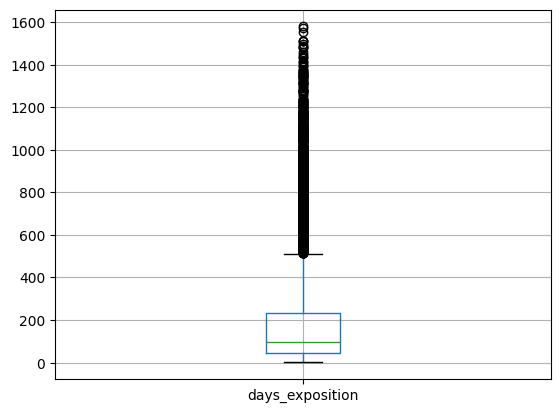

In [41]:
real_estate.boxplot('days_exposition')

- The upper bound after which the data can be considered outliers is estimated at about 500 days. But the outliers are very large (up to 1600 days), so the plot is not very informative. Calculate the upper bound manually.
75%Q + 1.5 \* IQR = 232 + 1.5\*(232 - 45) = 512
- A selling time of more than **512 days** can be considered unusually long.

### 4.3 Rare and Outlying Values

- The number of rooms (column `rooms`) was examined earlier. The zero values with a total area < 40 sq m were replaced with 1. 9 zero values remain. They can be dropped without damage to the sample distribution.

In [42]:
real_estate = real_estate.loc[real_estate['rooms'] != 0]

- Examine the ceiling height (column `ceiling_height`). The values < 2.5 m and > 4.1 m are most likely wrong. There is little such data (about 1%), so it can be dropped without damage to the distribution.

In [43]:
real_estate = real_estate.loc[(real_estate['ceiling_height'].isna()) | ((real_estate['ceiling_height'] >= 2.5) \
                              & (real_estate['ceiling_height'] <= 4.1))]

Update the indexes of the table after dropping the rows with reset_index().

In [44]:
real_estate = real_estate.reset_index(drop=True)

<a id='section4.4'></a>
### 4.4 Factors That Affect the Price of an Apartment

- Examine the influence on the price `last_price` of: the area `total_area`, the number of rooms `rooms`, the distance to the center `cityCenters_nearest`, the floor category `floor_cat`, and the publication date: weekday, month and year (parameters `publish_weekday`, `publish_month` and `publish_year` respectively).
- Plot the dependencies of these parameters (scatter plot) with plot().
- Limit the apartment price to 3.6 * 10^7 (99% of all values). The other values are considered outliers.
- Also calculate the Pearson correlation coefficient for each pair of parameters.

Create a helper function for plotting scatter plots.

In [45]:
def last_price_scatter(column, xrange, need_median=False):
    """
    input: column (str) - name of the column for the X axis of the plot
           xrange (tuple) - limits of the values in the column for the plot
           need_median (bool) - flag for plotting the median curve (for categorical data on the X axis)
    output: None
    The function builds a scatter plot of the apartment price 'last_price' against the parameter column.
    With need_median=True it also calculates the median 'last_price' for each value of column
    and plots the median curve in the same axes.
    """
    ax = real_estate.plot(x = column,
                          y = 'last_price',
                          kind = 'scatter',         # plot type
                          style = 'o',              # show the data as points
                          alpha = 0.3,              # transparency (to visualize the data density)
                          figsize = (8, 4),         # plot size
                          xlim = xrange,            # limits of the x axis
                          ylim = (0, 3.6*10**7),    # limits of the y axis
                          grid = True               # show the grid
                         )
    if need_median:
        # group the listings by column and find the median apartment prices for each group
        (real_estate
         .groupby(column)['last_price']
         .agg(['median'])
         # show the median apartment prices for the different groups
         .plot(ax = ax,
               y = 'median',
               style = '-or',
               legend = True,          # show the plot legend
               label = 'median',    # curve name
               grid = True              # show the grid
              )
        )      
        
    plt.show()

**1)** Dependency of `last_price` on `total_area`.
Limit the area to 198 (99% of all values) to discard rare outliers for clarity.

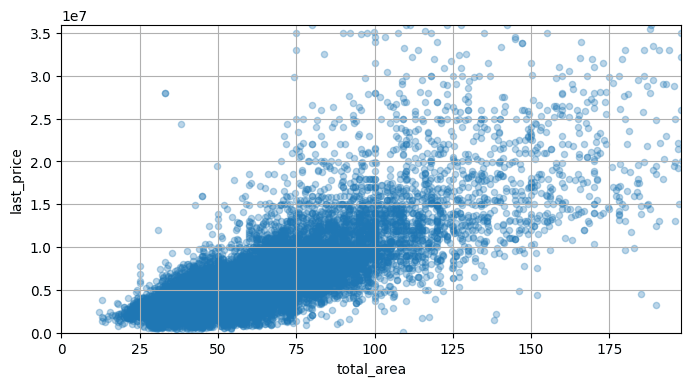

Pearson correlation coefficient between last_price and total_area: 0.646


In [46]:
# plot with the function last_price_scatter()
last_price_scatter('total_area', xrange=(0, 198))

# calculate the Pearson correlation coefficient with corr()
print('Pearson correlation coefficient between last_price and total_area:', \
      round(real_estate['last_price'].corr(real_estate['total_area']), 3))

- The plot shows that on average the apartment price grows with the total area.
- The Pearson correlation coefficient of 0.646 also confirms the positive dependency. The value of the coefficient is not very high, so the dependency between the parameters is rather weak.

**2)** Dependency of `last_price` on `rooms`.
Limit the number of rooms to 7 (99% of all values) to discard rare outliers for clarity.

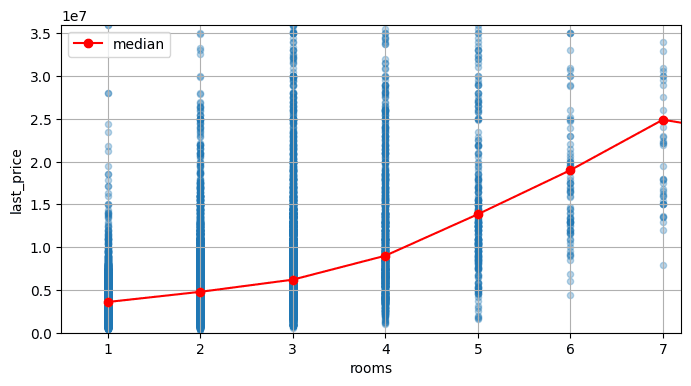

Pearson correlation coefficient between last_price and rooms: 0.361


In [47]:
# plot with the function last_price_scatter()
last_price_scatter('rooms', xrange=(0.5, 7.2), need_median=True)

# calculate the Pearson correlation coefficient with corr()
print('Pearson correlation coefficient between last_price and rooms:', \
      round(real_estate['last_price'].corr(real_estate['rooms']), 3))

- The plot shows that on average the apartment price grows with the number of rooms.
- The Pearson correlation coefficient of 0.361 also confirms the positive dependency. The value of the coefficient is low, so the dependency between the parameters is rather weak.

**3)** Dependency of `last_price` on `cityCenters_nearest`.
Limit the distance to the center to 50067 (99th percentile) to discard rare outliers for clarity.

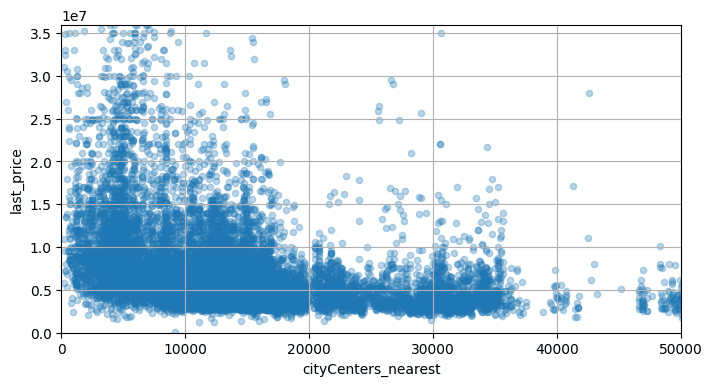

Pearson correlation coefficient between last_price and cityCenters_nearest: -0.205


In [48]:
# plot with the function last_price_scatter()
last_price_scatter('cityCenters_nearest', xrange=(0, 50067))

# calculate the Pearson correlation coefficient with corr()
print('Pearson correlation coefficient between last_price and cityCenters_nearest:', \
      round(real_estate['last_price'].corr(real_estate['cityCenters_nearest']), 3))

- The plot shows that on average the apartment price falls with the distance to the center.
- The Pearson correlation coefficient of -0.205 also confirms the negative dependency. The value of the coefficient is low, so the dependency between the parameters is rather weak.

**4)** Dependency of `last_price` on `floor_cat`.

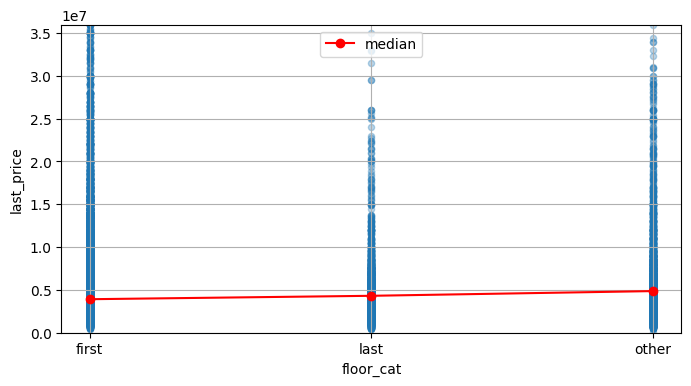

In [49]:
# plot with the function last_price_scatter()
last_price_scatter('floor_cat', xrange=(-0.1, 2.1), need_median=True)

- The plot shows that on average the apartment price practically does not depend on the floor. The prices on the first floor are slightly lower, but the difference is insignificant.

**5)** Dependency of `last_price` on `publish_weekday`.

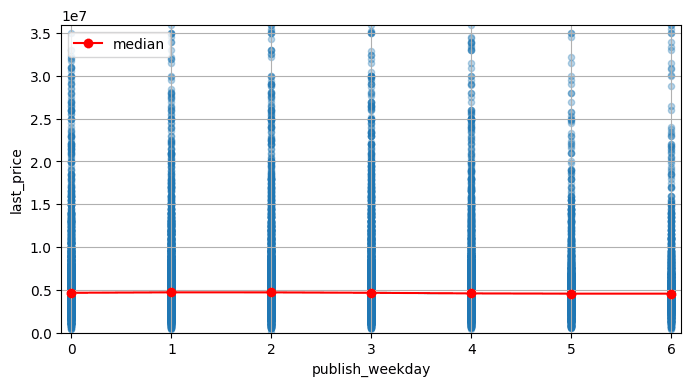

In [50]:
# plot with the function last_price_scatter()
last_price_scatter('publish_weekday', xrange=(-0.1, 6.1), need_median=True)

- The plot shows that on average the apartment price does not depend on the weekday of the listing publication.

**6)** Dependency of `last_price` on `publish_month`.

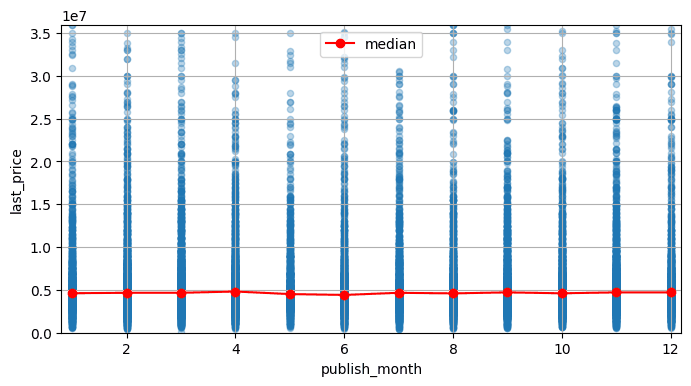

In [51]:
# plot with the function last_price_scatter()
last_price_scatter('publish_month', xrange=(0.8, 12.2), need_median=True)

- The plot shows that on average the apartment price does not depend on the month of the listing publication.

**7)** Dependency of `last_price` on `publish_year`.

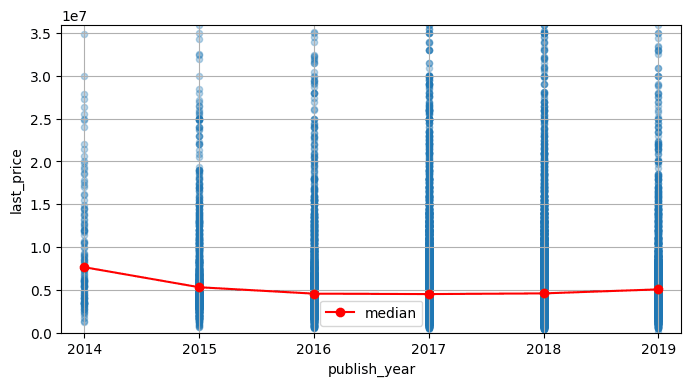

In [52]:
# plot with the function last_price_scatter()
last_price_scatter('publish_year', xrange=(2013.8, 2019.2), need_median=True)

- The plot shows that apartment prices fell from 2014 to 2016. From 2017 to 2019 there is an insignificant rise in prices.

### 4.5 Price per Square Meter in Different Localities

Group the listings by locality name, count the records in each group and calculate the median price per square meter. Then sort the result by the number of records in descending order and select the first 10 groups. Save the result in the variable `localities`.

In [53]:
localities = (real_estate
              .groupby('locality_name')['meter_price']
              .agg(['count', 'mean'])
              .sort_values(by='count', ascending=False)
              .head(10)
             )
display(localities)

,count,mean
locality_name,,
Санкт-Петербург,15557,114694.621617
посёлок Мурино,518,85645.902703
посёлок Шушары,439,78551.343964
Всеволожск,396,68670.461364
Пушкин,365,103079.872329
Колпино,337,75443.975668
посёлок Парголово,326,90205.425460
Гатчина,306,68757.679085
деревня Кудрово,298,92547.788255


Calculate the 99th percentile of the price per square meter. Use it as the upper limit of the plot (1% of rare values is discarded to make the plot clearer).

In [54]:
print('99th percentile of meter_price:', round(real_estate['meter_price'].quantile(0.99), 1))

99th percentile of meter_price: 265974.4


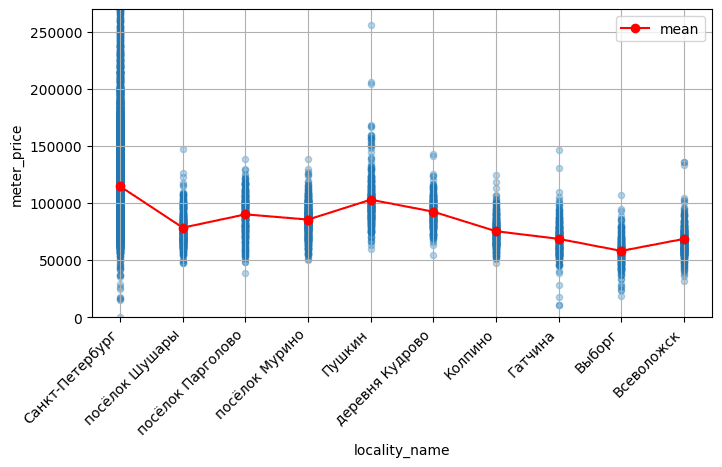

In [55]:
# plot the scatter plot of meter_price against locality_name
ax = (real_estate
 .query('locality_name in @localities.index')   # slice of the main table,
                                                # where locality_name matches the indexes of the table localities
 .plot(x = 'locality_name',
       y = 'meter_price',
       kind = 'scatter',         # plot type
       style = 'o',              # show the data as points
       alpha = 0.3,              # transparency (to visualize the data density)
       figsize = (8, 4),         # plot size
       ylim = (0, 2.7*10**5),    # limits of the y axis
       )
     )

# save in the variable `locals_list` the list of localities in the same order as on the plot
locals_list = real_estate.query('locality_name in @localities.index')['locality_name'].unique()
# change the order of the indexes in localities to show the medians correctly on the plot.
localities = localities.reindex(locals_list)
# show the medians of the price per square meter on the plot with the data
localities.plot(ax=ax,           # reuse the axes of the previous plot
                y = 'mean',    # medians of the price per square meter on the y axis
                style = '-or',   # curve style - red line with points at the calculated values
                grid = True      # show the grid on the plot
               )

# rotate the locality names by 45 degrees counterclockwise
plt.xticks(rotation=45, ha='right')
plt.show()

- The highest average housing price is in Saint Petersburg: 114694.6 per square meter.
- The lowest average housing price is in Vyborg: 58190.1 per square meter.

### 4.6 Boundary of the Central District in Saint Petersburg

**Task:** find out which area belongs to the center.
Select the apartments in Saint Petersburg (`locality_name`) with loc and save them in the variable `real_estate_peter`.
Create the column `dist_center` with the distance to the center in kilometers, rounded to integers.
Calculate the average price for each kilometer. Plot the dependency of the price on the distance to the center.
Find the boundary where the plot changes sharply. This is the central zone.

In [56]:
# get a slice of the data with query and save it in the table real_estate_peter
# reset the indexes with reset_index(drop=True)
real_estate_peter = (real_estate
                     .query('locality_name == "Санкт-Петербург"')   # "Санкт-Петербург" is the dataset value for Saint Petersburg
                     .reset_index(drop=True)
                    )

# save the distance to the center in kilometers in dist_center, round the value with round()
real_estate_peter['dist_center'] = round(real_estate_peter['cityCenters_nearest'] / 1000, 0)

Create a helper function for plotting scatter plots for apartments in the center of Saint Petersburg.

In [57]:
def peter_last_price_scatter(column, xrange, need_median=False, center_data=False):
    """
    input: column (str) - name of the column for the X axis of the plot
           xrange (tuple) - limits of the values in the column for the plot
           need_median (bool) - flag for plotting the median curve (for categorical data on the X axis)
           center_data (bool) - flag for plotting the data for apartments in the central district
    output: None
    The function builds a scatter plot of the price per square meter 'meter_price' against the parameter column.
    With need_median=True it also calculates the median 'meter_price' for each value of column
    and plots the median curve in the same axes.
    With center_data=True the function builds the same plots in the same axes for apartments in the city center
    The data is taken from the table of Saint Petersburg apartments `real_estate_peter`
    The data for the center of Saint Petersburg is taken from the table `real_estate_center`
    """
    # build the scatter plot of the price against the distance to the center
    ax = real_estate_peter.plot(x = column,
                    y = 'last_price',
                    kind = 'scatter',         # plot type
                    style = 'o',              # show the data as points
                    alpha = 0.3,              # transparency (to visualize the data density)
                    figsize = (8, 4),         # plot size
                    ylim = (0, 3.6*10**7),    # limits of the y axis
                    xlim = xrange,
                    grid = True
                    )
    if need_median:
        # group the data by the distance to the center and calculate the median price
        (real_estate_peter
         .groupby(column)['last_price']
         .agg(['median'])
         # on the same axes show the curve of the median price against the distance to the center.
         .plot(ax=ax,                   # reuse the axes of the previous plot
               y = 'median',            # medians of the price on the y axis
               style = '-or',           # curve style - red line with points at the calculated values
               legend = True,              # show the plot legend
               label = 'median peter',    # curve name
               grid = True              # show the grid on the plot
              )
        )
    
    # if needed, plot the data from another table on the same axes
    if center_data:
        real_estate_center.plot(ax=ax,
                              x = column,
                              y = 'last_price',
                              kind = 'scatter',         # plot type
                              style = 'o',              # show the data as points
                              color = 'green',
                              alpha = 0.3,              # transparency (to visualize the data density)
                              figsize = (8, 4),         # plot size
                              xlim = xrange,            # limits of the x axis
                              ylim = (0, 3.6*10**7),    # limits of the y axis
                              grid = True               # show the grid
                              )
        if need_median:
            # group the listings by column and find the median apartment prices for each group
            (real_estate_center
             .groupby(column)['last_price']
             .agg(['median'])
             # show the median apartment prices for the different groups
             .plot(ax = ax,
                   y = 'median',
                   style = '-oy',
                   legend = True,              # show the plot legend
                   label = 'median center',    # curve name
                   grid = True                 # show the grid
                  )
            )
        
    plt.show()

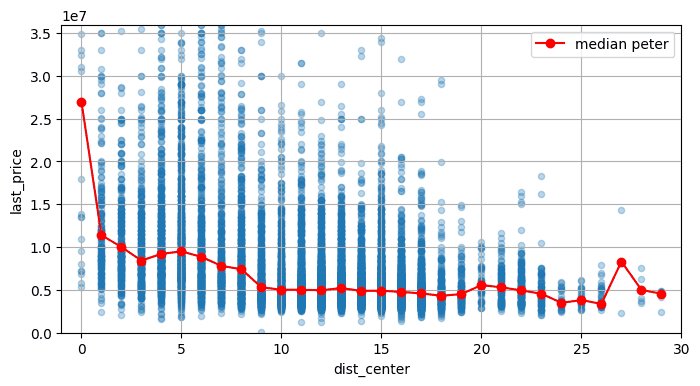

In [58]:
peter_last_price_scatter('dist_center', xrange=(-1,30), need_median=True)

- The apartment price starts to grow quickly at a distance to the center <= 3 km. The boundary of the central district is taken as **3 km**.

### 4.7 Apartments in the Central District of Saint Petersburg

**1)** Save the listings of apartments in the center of Saint Petersburg in the table `real_estate_center`.

In [59]:
# Take a slice of the table `real_estate_peter` where the distance to the center is up to 3 km.
# save the result in the table `real_estate_center`
real_estate_center = (real_estate_peter
                      .query('dist_center <= 3')
                      .reset_index(drop=True)
                     )

**2)** Analyze this area and examine the following parameters: area, price, number of rooms, ceiling height.

Create a helper function that plots two histograms (for all listings and for apartments in the center of Saint Petersburg) in the same axes to compare different parameters.

In [60]:
def show_histograms(column, bins, lims):
    """
    input: column (str) - name of the column for the histogram
           bins (int)   - number of bins for the histograms
           lims (tuple) - limits of the values in the column for the histograms
    output: None
    The function builds two histograms from the tables real_estate_peter and real_estate_center for the column
    in the same axes. The histograms show the density of the value distribution for clarity.
    """
    ax = real_estate_peter.plot(kind = 'hist',
                          y = column,
                          histtype = 'step',       # this type is convenient for comparing two histograms
                          bins = bins,
                          range = lims,
                          alpha = 0.5,
                          linewidth = 2,           # line width
                          grid = True,
                          density = True,          # show the density of the distribution
                          legend = True,           # show the legend
                          label = column + ' all'  # label of the plot
                         )
    real_estate_center.plot(kind = 'hist',
                            y = column,
                            histtype = 'step',
                            ax = ax,               # plot in the axes of the previous histogram
                            bins = bins,
                            range = lims,
                            alpha = 0.5,
                            linewidth = 2,
                            grid = True,
                            density = True,
                            legend = True,
                            label = column + ' center'
                           )
    # density=True is needed to show two histograms in the same axes.
    plt.show()

count    866.000000
mean      98.682356
std       56.628284
min       12.000000
25%       63.400000
50%       85.000000
75%      116.500000
max      517.000000
Name: total_area, dtype: float64

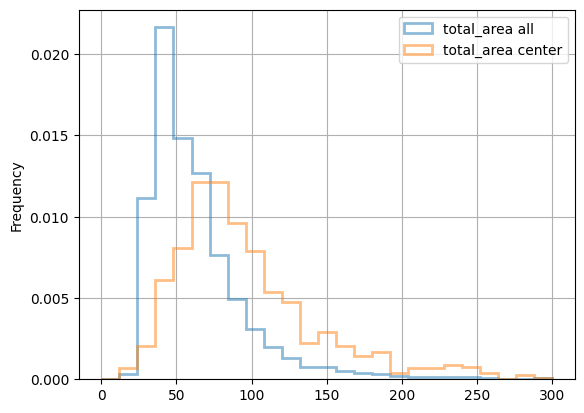

In [61]:
# print the distribution of the area 'total_area' for apartments in the center of Saint Petersburg with describe()
display(real_estate_center['total_area'].describe())

# plot the histogram of 'total_area' with hist().
# split the histogram into 25 bins, limit 'total_area' to < 300 (sq m) (99% of the data)
show_histograms('total_area', bins=25, lims=(0, 300))

- The mean and the median of `total_area` for apartments in the center are 98.7 and 85.0 respectively.
The mean and the median of `total_area` for all apartments in the city are lower: 64.5 and 55.0 respectively.
- The histograms also show clearly the shift towards larger values for apartments in the center (on both sides of the histogram peaks).

count    8.660000e+02
mean     1.498426e+05
std      1.253362e+05
min      2.891960e+04
25%      9.646785e+04
50%      1.172644e+05
75%      1.513040e+05
max      1.736842e+06
Name: meter_price, dtype: float64

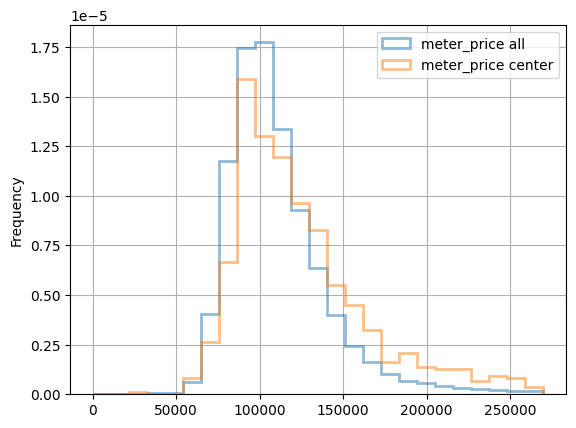

In [62]:
# print the distribution of the price per square meter 'meter_price' for apartments in the center of Saint Petersburg
display(real_estate_center['meter_price'].describe())

# plot the histogram of 'meter_price' with hist().
# split the histogram into 25 bins, limit 'meter_price' to (0, 2.7*10**5) (99% of the data)
show_histograms('meter_price', bins=25, lims=(0, 2.7*10**5))

- The mean and the median of `meter_price` for apartments in the center are 1.25 and 1.17 (\*10^5) respectively.
The mean and the median of `meter_price` for all apartments are lower: 1.15 and 1.05 (\*10^5) respectively.
- The histograms also show a small shift towards larger values for apartments in the center (on both sides of the histogram peaks).

count    866.000000
mean       3.121247
std        1.479052
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       14.000000
Name: rooms, dtype: float64

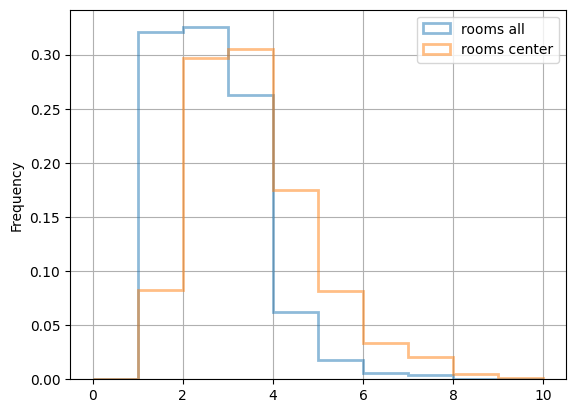

In [63]:
# print the distribution of the number of rooms 'rooms' for apartments in the center of Saint Petersburg
display(real_estate_center['rooms'].describe())

# plot the histogram of 'rooms' with hist().
# split the histogram into 10 bins, limit 'rooms' to (0, 10) (99% of the data)
show_histograms('rooms', bins=10, lims=(0, 10))

- The mean and the median of `rooms` for apartments in the center are 3.
The mean and the median of `rooms` for all apartments are lower: 2.
- The histograms also show clearly the shift towards larger values for apartments in the center (on both sides of the histogram peaks).

count    600.000000
mean       3.192267
std        0.337210
min        2.500000
25%        3.000000
50%        3.200000
75%        3.400000
max        4.100000
Name: ceiling_height, dtype: float64

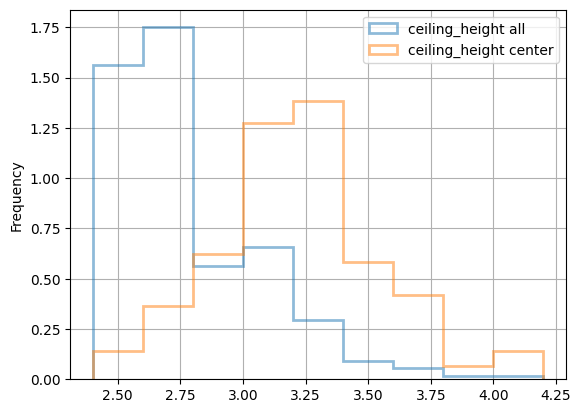

In [64]:
# print the distribution of the ceiling height 'ceiling_height' for apartments in the center of Saint Petersburg
display(real_estate_center['ceiling_height'].describe())

# plot the histogram of 'ceiling_height' with hist().
# split the histogram into 9 bins, limit 'ceiling_height' to (2.4, 4.2) (99% of the data)
show_histograms('ceiling_height', bins=9, lims=(2.4, 4.2))

- The mean and the median of `ceiling_height` for apartments in the center are 3.19 and 3.2 respectively.
The mean and the median of `ceiling_height` for all apartments are lower: 2.76 and 2.7 respectively.
- The histograms also show clearly the shift towards larger values for apartments in the center (on both sides of the histogram peaks).

**3)** Find the factors that affect the apartment price (number of rooms, floor, distance to the center, listing date).

- Examine the dependency of the apartment price `last_price` on the number of rooms `rooms` for all listings and for apartments in the center.

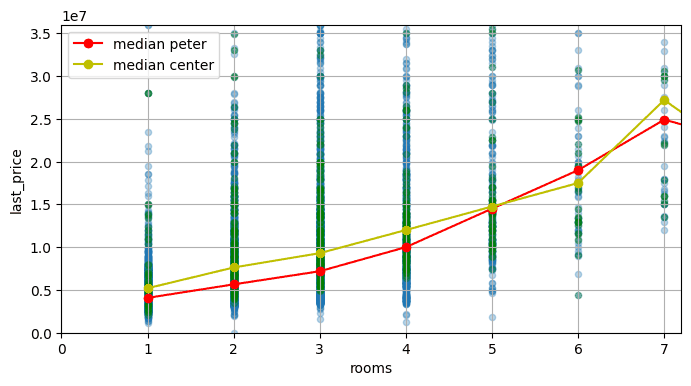

Pearson correlation coefficient between last_price and rooms for the whole city: 0.369
Pearson correlation coefficient between last_price and rooms in the city center: 0.237


In [65]:
# plot with the function peter_last_price_scatter()
peter_last_price_scatter('rooms', xrange=(0, 7.2), need_median=True, center_data=True)

# calculate the Pearson correlation coefficient with corr()
print('Pearson correlation coefficient between last_price and rooms for the whole city:', \
      round(real_estate_peter['last_price'].corr(real_estate_peter['rooms']), 3))
print('Pearson correlation coefficient between last_price and rooms in the city center:', \
      round(real_estate_center['last_price'].corr(real_estate_center['rooms']), 3))

- The plot shows that for a small number of rooms the median `last_price` is slightly higher for apartments in the center. For 6 rooms and more there is practically no difference in price. Possibly there is not enough data for a more accurate estimate, and the information for a large number of rooms is unreliable.
- The Pearson correlation coefficient for apartments in the center is 0.237, lower than for the whole city (0.369). This may be caused by the generally higher prices of apartments in the city center.

- Examine the dependency of the apartment price `last_price` on the floor `floor_cat` for all listings and for apartments in the center.

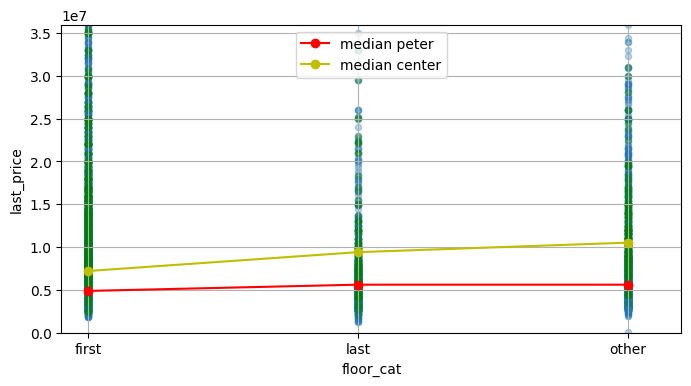

In [66]:
# plot with the function peter_last_price_scatter()
peter_last_price_scatter('floor_cat', xrange=(-0.1, 2.2), need_median=True, center_data=True)

- The plot shows that the median `last_price` is slightly higher for apartments in the center for all values of `floor_cat`. This is caused by the generally higher prices of apartments in the central district.

- Examine the dependency of the apartment price `last_price` on the distance to the center `cityCenters_nearest` for all listings and for apartments in the center.

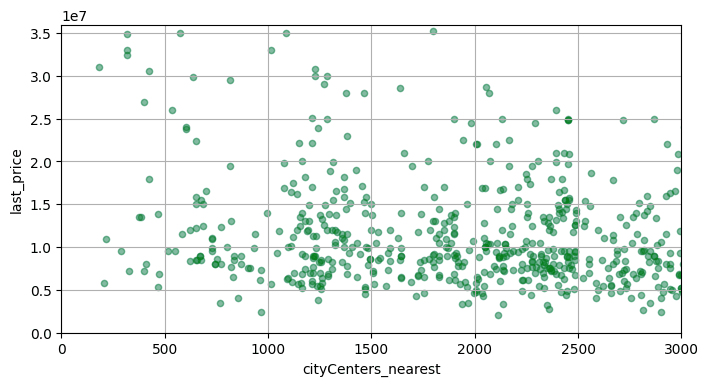

Pearson correlation coefficient between last_price and cityCenters_nearest for apartments in the center: -0.257
Pearson correlation coefficient between last_price and cityCenters_nearest for all apartments: -0.163


In [67]:
# plot with the function peter_last_price_scatter()
peter_last_price_scatter('cityCenters_nearest', xrange=(0, 3000), center_data=True)

# calculate the Pearson correlation coefficient with corr()
print('Pearson correlation coefficient between last_price and cityCenters_nearest for apartments in the center:', \
      round(real_estate_peter['last_price'].corr(real_estate_peter['cityCenters_nearest']), 3))
print('Pearson correlation coefficient between last_price and cityCenters_nearest for all apartments:', \
      round(real_estate_center['last_price'].corr(real_estate_center['cityCenters_nearest']), 3))

- The Pearson correlation coefficient for apartments in the center is -0.163, slightly smaller in absolute value than for apartments in the whole city (-0.257). The dependency between the distance to the center and the apartment price is slightly stronger for apartments in the whole city. But there is not much data for apartments in the center, so the information may be unreliable.

- Examine the dependency of the apartment price `last_price` on the year `publish_year` for all listings and for apartments in the center.

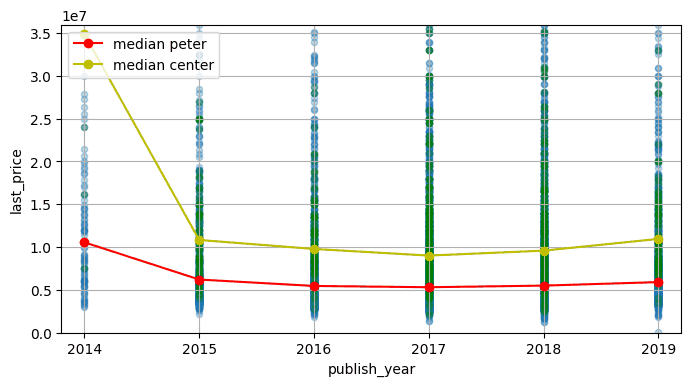

In [68]:
# plot with the function peter_last_price_scatter()
peter_last_price_scatter('publish_year', xrange=(2013.8, 2019.2), need_median=True, center_data=True)

- The plot shows that the median `last_price` is almost 2 times higher for apartments in the center for listings after 2015 `publish_year`. This is caused by the generally higher prices of apartments in the central district.
- From 2014 to 2015 the prices of apartments in the central district fell more sharply than the prices of listings in the whole city.

### Conclusions

- The parameters of the apartments are examined: area, price, number of rooms, ceiling height. The data distributions are close to the Poisson distribution.
- Anomalous data (zero numbers of rooms, etc.) is found and corrected where possible, and small implausible outliers are dropped.
- The time of selling the apartments is examined. The distribution is close to the Poisson distribution. No anomalous peaks are found in the histogram. The data is strongly skewed to the left (the mean is 2 times larger than the median). Most apartments are sold in 45-232 days. Selling times shorter than 4 days and longer than 512 days can be considered unusual outliers.
- The factors that affect the apartment price are analyzed. The highest correlation is shown by the total area `total_area`, the number of rooms `rooms` and the distance to the city center `cityCenters_nearest`. The dependency of the price on the listing year `publish_year` is also found. It may be caused by fluctuations of the real estate market.
- The price per square meter in different localities is analyzed. Saint Petersburg is the most expensive (114694.6), and the lowest price per square meter is in Vyborg (58190.1).
- The dependency of the price per square meter on the distance to the city center in Saint Petersburg is analyzed. The boundary of the central district is about 3 km.
- The factors that affect the apartment price in Saint Petersburg and its center are examined. The generally higher prices of apartments in the central district are noted. Otherwise the correlations do not differ much. A sharp fall in the apartment price in the central district in 2014-2015 is noted (about 3.5 times).

## Step 5. Overall Conclusion

**1)** The data in the table real_estate_data.csv on apartment sales contains a lot of missing information (from 5 to 65% of missing values in different columns). Part of the information may have been lost because of system failures when the data was uploaded or exported. Part of the information may have been absent initially (the listings were not filled in 100%). The information was restored from the existing data of other parameters, or left as it is.
**2)** Anomalous and implausible data was partially corrected based on the table data. Small outliers (up to 1%) that do not affect the overall data distribution were dropped. The data types were also corrected according to the logic of the stored information.
**3)** Additional parameters (price per square meter, publication year, floor categories of apartments, etc.) were calculated and added to the source table for further analysis.
**4)** The distributions of the apartment parameters (area, price, number of rooms, ceiling height) are close to the Poisson distribution. No anomalous peaks were noticed after the data transformation.
**5)** The time of selling apartments has quite a large spread: 45-232 days. Times shorter than 4 days or longer than 512 days can be considered outliers. This may indicate instability of the real estate market.
**6)** The price of an apartment is affected the most by the total area, the number of rooms and the distance to the center. A fall in real estate prices in 2014-2015 is also noted (especially for apartments in the central district of Saint Petersburg).
**7)** The price per square meter in different localities is analyzed. Saint Petersburg is the most expensive (114694.6), and the lowest price per square meter is in Vyborg (58190.1).
**8)** Judging by the change of the price per square meter, the boundary of the central district of Saint Petersburg is about 3 km.
**9)** The factors that affect the apartment prices in Saint Petersburg are stronger for the city as a whole than for its central district (the correlation coefficients are smaller for the central district). But the differences are small (the difference in the Pearson correlation coefficients is 0.1-0.15). This may be caused by the generally higher prices of apartments in the central district.